# Ω Omega Capital · Rates Research
## The 2026 Global Bond Selloff: charts & analysis

**Charts:** §01 Global 30Y yields · §02 PCA of the US curve · §03 France vs Germany · §04 Volatility regimes · §05 Oil and yields

**Run:** `Kernel → Restart & Run All`. Expects a `data/` folder next to this notebook. Charts are saved as 300-dpi PNGs in `charts/`.

**Needs:** pandas, numpy, matplotlib, statsmodels (`pip3 install statsmodels`).

### 0 · Setup, load and check data

In [1]:
from pathlib import Path
import shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

# --- paths: data/ next to this notebook (fallback: ~/data)
DATA = Path("data") if Path("data").is_dir() else Path.home() / "data"
FIG = Path("charts"); FIG.mkdir(exist_ok=True)
print("Data folder:", DATA.resolve())

# --- map Investing.com download names to standard names (newest download wins)
RENAME = {
    "Brent Oil Futures Historical Data":                 "BRENT",
    "France 2-Year Bond Yield Historical Data":          "FR_2Y",
    "France 10-Year Bond Yield Historical Data":         "FR_10Y",
    "France 30-Year Bond Yield Historical Data":         "FR_30Y",
    "Italy 10-Year Bond Yield Historical Data":          "IT_10Y",
    "United Kingdom 30-Year Bond Yield Historical Data": "UK_30Y",
}
for prefix, std in RENAME.items():
    hits = sorted(DATA.glob(f"{prefix}*.csv"), key=lambda p: p.stat().st_mtime)
    if hits:
        shutil.copy(hits[-1], DATA / f"{std}.csv")

EXPECTED = ["US_3M", "US_1Y", "US_2Y", "US_5Y", "US_7Y", "US_10Y", "US_20Y", "US_30Y",
            "UK_30Y", "DE_2Y", "DE_10Y", "DE_30Y", "FR_2Y", "FR_10Y", "FR_30Y",
            "IT_10Y", "JP_30Y", "BRENT"]
missing = [n for n in EXPECTED if not (DATA / f"{n}.csv").exists()]
print("Missing files:", missing or "none")

# --- loader: handles script files (2026-10-14) and Investing.com files (10/14/2026, newest first)
DATE_FORMATS = ["%Y-%m-%d", "%m/%d/%Y", "%d/%m/%Y", "%d.%m.%Y", "%b %d, %Y"]

def parse_dates(s):
    s = s.astype(str).str.strip()
    best = None
    for f in DATE_FORMATS:
        d = pd.to_datetime(s, format=f, errors="coerce")
        if best is None or d.notna().sum() > best.notna().sum():
            best = d
    return best

def load(name):
    df = pd.read_csv(DATA / f"{name}.csv", encoding="utf-8-sig")
    df.columns = [c.strip().strip('"') for c in df.columns]
    price = pd.to_numeric(df["Price"].astype(str).str.replace(",", ""), errors="coerce")
    s = pd.Series(price.values, index=parse_dates(df["Date"]), name=name)
    s = s[s.index.notna()].dropna().sort_index()
    return s[~s.index.duplicated()]

px = pd.concat({n: load(n) for n in EXPECTED if n not in missing}, axis=1).loc["2016-01-01":]
YIELDS = [c for c in px.columns if c != "BRENT"]

# --- data check
def biggest_move(c):
    d = px[c].dropna().diff()
    d = d * 100 if c in YIELDS else d / px[c].dropna().shift() * 100
    return pd.Series({"max |1d move|": round(d.abs().max(), 1), "on": d.abs().idxmax().date()})

summary = pd.concat([pd.DataFrame({
    "first": px.apply(lambda c: c.first_valid_index().date()),
    "last":  px.apply(lambda c: c.last_valid_index().date()),
    "obs":   px.count(),
    "last value": px.apply(lambda c: c.dropna().iloc[-1]).round(3),
    "min": px.min().round(2), "max": px.max().round(2)}),
    px.columns.to_series().apply(biggest_move)], axis=1)
print("Units: yields in %, Brent in USD/bbl; 1d move in bp (yields) or % (Brent)")
display(summary)

short = [c for c in px.columns if px[c].first_valid_index() > pd.Timestamp("2016-03-31")]
if short:
    print("WARNING: these series start after Q1 2016, so the download was cut short. "
          "Re-download from 01/01/2016:", short)
AS_OF = px.index.max().date()
print("Data as of:", AS_OF)

Data folder: /Users/lwuqiu/bond-analysis/data
Missing files: none
Units: yields in %, Brent in USD/bbl; 1d move in bp (yields) or % (Brent)


,first,last,obs,last value,min,max,max |1d move|,on
US_3M,2016-01-04,2026-10-13,2695,4.260,0.00,5.63,34.0,2022-06-13
US_1Y,2016-01-04,2026-10-13,2695,4.480,0.04,5.49,60.0,2023-03-13
US_2Y,2016-01-04,2026-10-13,2695,4.790,0.09,5.19,57.0,2023-03-13
US_5Y,2016-01-04,2026-10-13,2695,5.000,0.19,5.09,32.0,2022-11-10
US_7Y,2016-01-04,2026-10-13,2695,5.110,0.36,5.19,31.0,2022-11-10
US_10Y,2016-01-04,2026-10-13,2695,5.210,0.52,5.31,30.0,2022-11-10
US_20Y,2016-01-04,2026-10-13,2695,5.600,0.87,5.71,35.0,2020-03-17
US_30Y,2016-01-04,2026-10-13,2695,5.560,0.99,5.67,31.0,2020-03-06
UK_30Y,2026-09-15,2026-10-15,23,5.839,5.70,5.98,9.9,2026-09-17
DE_2Y,2016-01-04,2026-10-15,2739,3.070,-1.02,3.32,36.0,2023-03-13


Data as of: 2026-10-15


In [2]:
# --- house style (swap the hex codes for Omega's brand colours)
COL = {"US": "#1F4E79", "UK": "#C0392B", "DE": "#2C3E50", "FR": "#7D3C98",
       "IT": "#1E8449", "JP": "#D4A017", "BRENT": "#8B5A2B",
       "ink": "#0B1320", "muted": "#6B7280", "grid": "#E3E7EE", "accent": "#C0392B"}

plt.rcParams.update({
    "figure.figsize": (10, 5.2), "figure.dpi": 110, "savefig.dpi": 300,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": COL["muted"], "axes.labelcolor": COL["ink"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COL["grid"], "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "legend.frameon": False, "xtick.color": COL["muted"], "ytick.color": COL["muted"],
})

def header(fig, title, subtitle):
    fig.text(0.01, 0.995, title, ha="left", va="top", fontsize=14, weight="bold", color=COL["ink"])
    fig.text(0.01, 0.955, subtitle, ha="left", va="top", fontsize=9.5, color=COL["muted"])

def finish(fig, name, source, top=0.925):
    fig.text(0.01, 0.005, f"Source: {source}; Omega Capital calculations. Data as of {AS_OF}.",
             fontsize=7.5, color=COL["muted"], ha="left")
    fig.text(0.99, 0.005, "Ω OMEGA CAPITAL · Rates Research", fontsize=8,
             color=COL["muted"], ha="right", weight="bold")
    fig.tight_layout(rect=(0, 0.03, 1, top))
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()
    print("saved:", FIG / f"{name}.png")

def month_axis(ax, fmt="%b"):
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))

BASE = "2026-01-01"

### §01 · The long end breaks: global 30Y yields
The change in each 30-year yield since its first close of 2026, and what that move did to the price of a 30-year par bond.

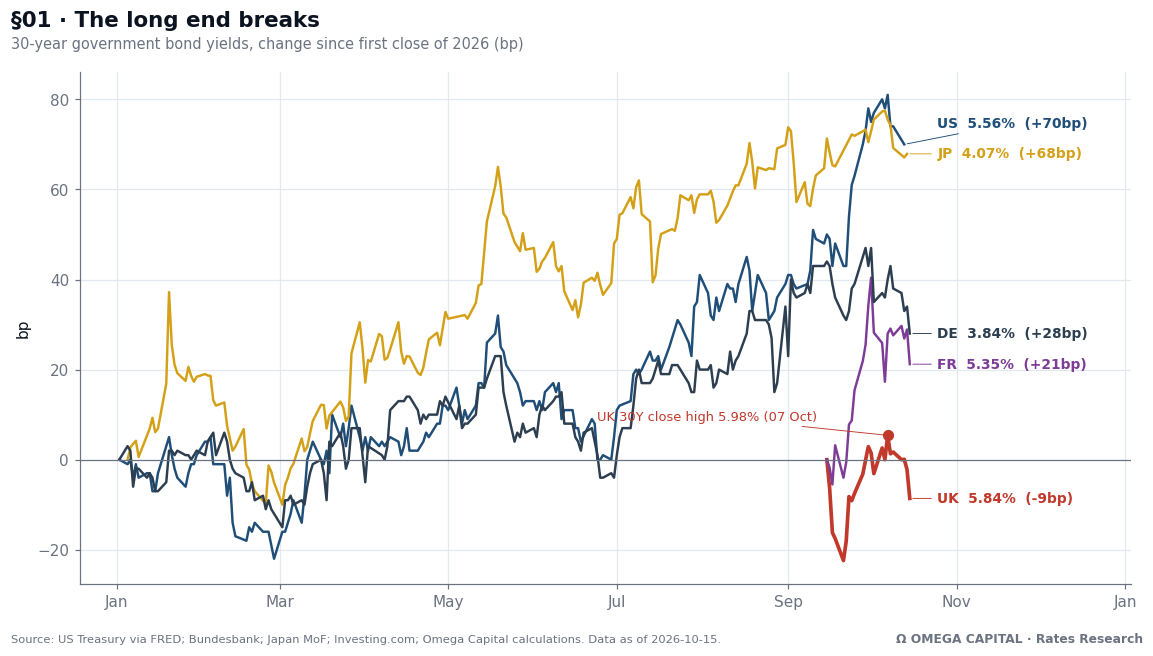

saved: charts/chart1_global_30y.png
Price change = 30Y par bond bought at the first 2026 close, repriced at today's yield. Price only: excludes coupon income and ageing.


,1st 2026 close (%),Latest (%),Change (bp),2026 high (%),High on,Mod. duration (yrs),30Y par bond price chg (%)
Market,,,,,,,
US,4.86,5.56,70,5.67,2026-10-07,15.7,-10.2
JP,3.39,4.07,68,4.17,2026-10-06,18.7,-11.7
DE,3.56,3.84,28,4.03,2026-09-29,18.3,-5.0
FR,5.14,5.35,21,5.55,2026-10-01,15.2,-3.1
UK,5.92,5.84,-9,5.98,2026-10-07,13.9,1.2


In [3]:
LONG = {"UK": "UK_30Y", "US": "US_30Y", "FR": "FR_30Y", "JP": "JP_30Y", "DE": "DE_30Y"}
LONG = {k: v for k, v in LONG.items() if v in px}

def bond_price(coupon, y, n=30, f=2):
    """Price per 100 of an n-year bullet bond, coupon and yield as decimals, f payments per year."""
    t = np.arange(1, n * f + 1)
    return np.sum(coupon / f * 100 / (1 + y / f) ** t) + 100 / (1 + y / f) ** (n * f)

def mod_duration(y, n=30, f=2, h=1e-4):
    return -(bond_price(y, y + h, n, f) - bond_price(y, y - h, n, f)) / (2 * h * 100)

fig, ax = plt.subplots(figsize=(10.5, 5.8))
rows, ends = [], []
for cc, col in LONG.items():
    s = px[col].loc[BASE:].dropna()
    chg = (s - s.iloc[0]) * 100
    ax.plot(chg.index, chg, color=COL[cc], lw=2.4 if cc == "UK" else 1.6)
    ends.append([cc, chg.index[-1], chg.iloc[-1], s.iloc[-1]])
    p_now = bond_price(s.iloc[0] / 100, s.iloc[-1] / 100)
    rows.append({"Market": cc, "1st 2026 close (%)": round(s.iloc[0], 2),
                 "Latest (%)": round(s.iloc[-1], 2), "Change (bp)": round(chg.iloc[-1]),
                 "2026 high (%)": round(s.max(), 2), "High on": s.idxmax().date(),
                 "Mod. duration (yrs)": round(mod_duration(s.iloc[0] / 100), 1),
                 "30Y par bond price chg (%)": round(p_now - 100, 1)})

ax.axhline(0, color=COL["muted"], lw=0.8)
lo, hi = ax.get_ylim(); gap = 0.06 * (hi - lo)
ends.sort(key=lambda e: e[2]); pos = [e[2] for e in ends]
for i in range(1, len(pos)):
    pos[i] = max(pos[i], pos[i - 1] + gap)
for (cc, x, yv, lvl), yl in zip(ends, pos):
    ax.annotate(f"{cc}  {lvl:.2f}%  ({yv:+.0f}bp)", xy=(x, yv), xytext=(px.index.max() + pd.Timedelta(days=10), yl),
                color=COL[cc], fontsize=9, weight="bold", va="center",
                arrowprops=dict(arrowstyle="-", color=COL[cc], lw=0.6))
ax.set_xlim(right=px.index.max() + pd.Timedelta(days=80))

if "UK" in LONG:
    uk = px["UK_30Y"].loc[BASE:].dropna()
    d_hi, y_hi = uk.idxmax(), (uk.max() - uk.iloc[0]) * 100
    ax.scatter([d_hi], [y_hi], s=40, color=COL["UK"], zorder=5)
    ax.annotate(f"UK 30Y close high {uk.max():.2f}% ({d_hi:%d %b})",
                xy=(d_hi, y_hi), xytext=(-190, 10), textcoords="offset points", fontsize=8.5,
                color=COL["UK"], arrowprops=dict(arrowstyle="-", color=COL["UK"], lw=0.6))

ax.set_ylabel("bp"); month_axis(ax)
header(fig, "§01 · The long end breaks", "30-year government bond yields, change since first close of 2026 (bp)")
finish(fig, "chart1_global_30y", "US Treasury via FRED; Bundesbank; Japan MoF; Investing.com")

table1 = pd.DataFrame(rows).set_index("Market").sort_values("Change (bp)", ascending=False)
print("Price change = 30Y par bond bought at the first 2026 close, repriced at today's yield. "
      "Price only: excludes coupon income and ageing.")
display(table1)

### §02 · Anatomy of the move: PCA of the US Treasury curve
Principal components of daily yield changes (8 tenors, 2016–today).
- **PC1 (level):** the whole curve moves together.
- **PC2 (slope):** the long end moves against the short end.
- **PC3 (curvature):** the belly moves against both wings.

The bottom-right panel splits the actual 2026 move by tenor into those three components.

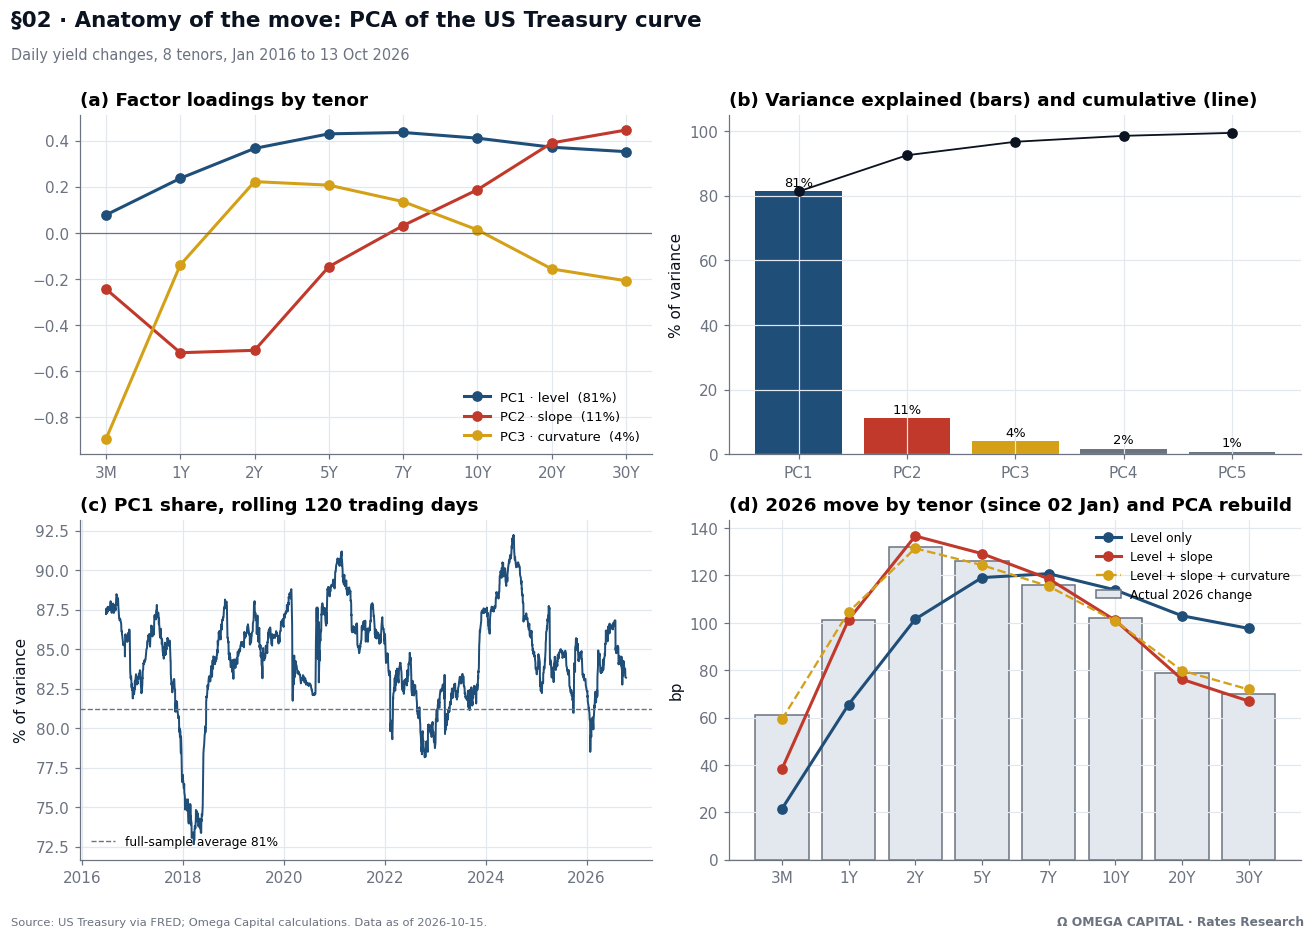

saved: charts/chart2_us_pca.png
Loadings (unit-length eigenvectors):


,PC1 · level,PC2 · slope,PC3 · curvature
3M,0.077,-0.244,-0.896
1Y,0.236,-0.521,-0.140
2Y,0.366,-0.510,0.222
5Y,0.429,-0.147,0.207
7Y,0.435,0.031,0.135
10Y,0.411,0.187,0.012
20Y,0.371,0.390,-0.157
30Y,0.352,0.446,-0.209



Attribution of the 2026 move (bp), since 2026-01-02:


,2Y,10Y,30Y,2s30s (30Y-2Y)
PC1 · level,101.5,113.9,97.6,-3.9
PC2 · slope,35.1,-12.8,-30.7,-65.7
PC3 · curvature,-5.2,-0.3,4.9,10.1
Residual (PC4-8),0.6,1.3,-1.9,-2.4
Actual,132.0,102.0,70.0,-62.0


PC1 share: full sample 81.2% | latest 120-day window 83.2% | 2026 average 83.9%


In [4]:
US_T = ["US_3M", "US_1Y", "US_2Y", "US_5Y", "US_7Y", "US_10Y", "US_20Y", "US_30Y"]
LAB = ["3M", "1Y", "2Y", "5Y", "7Y", "10Y", "20Y", "30Y"]
curve = px[US_T].dropna()
dY = curve.diff().dropna() * 100                     # daily changes, bp

def pca(X):
    cov = np.cov(X, rowvar=False)
    w, V = np.linalg.eigh(cov)
    o = w.argsort()[::-1]; w, V = w[o], V[:, o]
    if V[:, 0].sum() < 0: V[:, 0] *= -1                                  # level: positive
    if V[-1, 1] < V[0, 1]: V[:, 1] *= -1                                 # slope: long end up
    if V[3:5, 2].mean() < (V[0, 2] + V[-1, 2]) / 2: V[:, 2] *= -1        # curvature: belly up
    return w, V

w, V = pca(dY.values)
share = w / w.sum()

# rolling 120-day share of variance explained by PC1
WIN = 120
X = dY.values
roll = pd.Series([np.linalg.eigvalsh(np.cov(X[i - WIN:i], rowvar=False))[::-1][0] /
                  np.trace(np.cov(X[i - WIN:i], rowvar=False)) for i in range(WIN, len(X) + 1)],
                 index=dY.index[WIN - 1:])

# 2026 decomposition: cumulative change by tenor projected on the PCs (exact with all 8)
start = curve.loc[BASE:].index[0]
delta = (curve.iloc[-1] - curve.loc[start]).values * 100
scores = V.T @ delta
contrib = {f"PC{k+1}": scores[k] * V[:, k] for k in range(3)}

fig, axs = plt.subplots(2, 2, figsize=(12, 8.4))
names = ["PC1 · level", "PC2 · slope", "PC3 · curvature"]
cols = [COL["US"], COL["UK"], COL["JP"]]

ax = axs[0, 0]
for k in range(3):
    ax.plot(LAB, V[:, k], marker="o", color=cols[k], lw=2, label=f"{names[k]}  ({share[k]:.0%})")
ax.axhline(0, color=COL["muted"], lw=0.8)
ax.set_title("(a) Factor loadings by tenor"); ax.legend(fontsize=8.5)

ax = axs[0, 1]
bars = ax.bar([f"PC{k+1}" for k in range(5)], share[:5] * 100, color=[*cols, COL["muted"], COL["muted"]])
ax.plot([f"PC{k+1}" for k in range(5)], np.cumsum(share[:5]) * 100, color=COL["ink"], marker="o", lw=1.2)
for b, v in zip(bars, share[:5]):
    ax.text(b.get_x() + b.get_width() / 2, v * 100 + 1.5, f"{v:.0%}", ha="center", fontsize=8.5)
ax.set_ylim(0, 105); ax.set_ylabel("% of variance")
ax.set_title("(b) Variance explained (bars) and cumulative (line)")

ax = axs[1, 0]
ax.plot(roll.index, roll * 100, color=COL["US"], lw=1.3)
ax.axhline(share[0] * 100, color=COL["muted"], ls="--", lw=0.9, label=f"full-sample average {share[0]:.0%}")
ax.legend(fontsize=8, loc="lower left")
ax.set_ylabel("% of variance"); ax.set_title(f"(c) PC1 share, rolling {WIN} trading days")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax = axs[1, 1]
ax.bar(LAB, delta, color=COL["grid"], edgecolor=COL["muted"], label="Actual 2026 change")
ax.plot(LAB, contrib["PC1"], marker="o", color=cols[0], lw=2, label="Level only")
ax.plot(LAB, contrib["PC1"] + contrib["PC2"], marker="o", color=cols[1], lw=2, label="Level + slope")
ax.plot(LAB, contrib["PC1"] + contrib["PC2"] + contrib["PC3"], marker="o", color=cols[2], lw=1.5,
        ls="--", label="Level + slope + curvature")
ax.axhline(0, color=COL["muted"], lw=0.8); ax.set_ylabel("bp")
ax.set_title(f"(d) 2026 move by tenor (since {start:%d %b}) and PCA rebuild"); ax.legend(fontsize=8)

header(fig, "§02 · Anatomy of the move: PCA of the US Treasury curve",
       f"Daily yield changes, 8 tenors, {dY.index[0]:%b %Y} to {dY.index[-1]:%d %b %Y}")
finish(fig, "chart2_us_pca", "US Treasury via FRED")

# tables
load_tbl = pd.DataFrame(V[:, :3], index=LAB, columns=names).round(3)
idx = {t: LAB.index(t) for t in ["2Y", "10Y", "30Y"]}
attr = pd.DataFrame({n: {"2Y": c[idx["2Y"]], "10Y": c[idx["10Y"]], "30Y": c[idx["30Y"]],
                         "2s30s (30Y-2Y)": c[idx["30Y"]] - c[idx["2Y"]]}
                     for n, c in zip(names, contrib.values())}).T
attr.loc["Residual (PC4-8)"] = [delta[idx["2Y"]], delta[idx["10Y"]], delta[idx["30Y"]],
                                delta[idx["30Y"]] - delta[idx["2Y"]]] - attr.sum().values
attr.loc["Actual"] = [delta[idx["2Y"]], delta[idx["10Y"]], delta[idx["30Y"]], delta[idx["30Y"]] - delta[idx["2Y"]]]
print("Loadings (unit-length eigenvectors):"); display(load_tbl)
print(f"\nAttribution of the 2026 move (bp), since {start.date()}:"); display(attr.round(1))
print(f"PC1 share: full sample {share[0]:.1%} | latest {WIN}-day window {roll.iloc[-1]:.1%} | "
      f"2026 average {roll.loc[BASE:].mean():.1%}")

### §03 · France vs Germany: credit stress or term premium?
- **(a)** The 10Y OAT–Bund spread with rolling 1-year z-score bands.
- **(b)** The 2Y spread against the 10Y spread. If the 10Y spread is wide while the 2Y stays tight, markets fear long-run fiscal sustainability, not near-term default.
- **(c)** France minus Italy at 10Y.

*Methodology note:* Germany comes from the Bundesbank Svensson zero-coupon curve, while France and Italy are Investing.com benchmark yields. Levels can differ by a few bp because of method, but the moves are comparable.

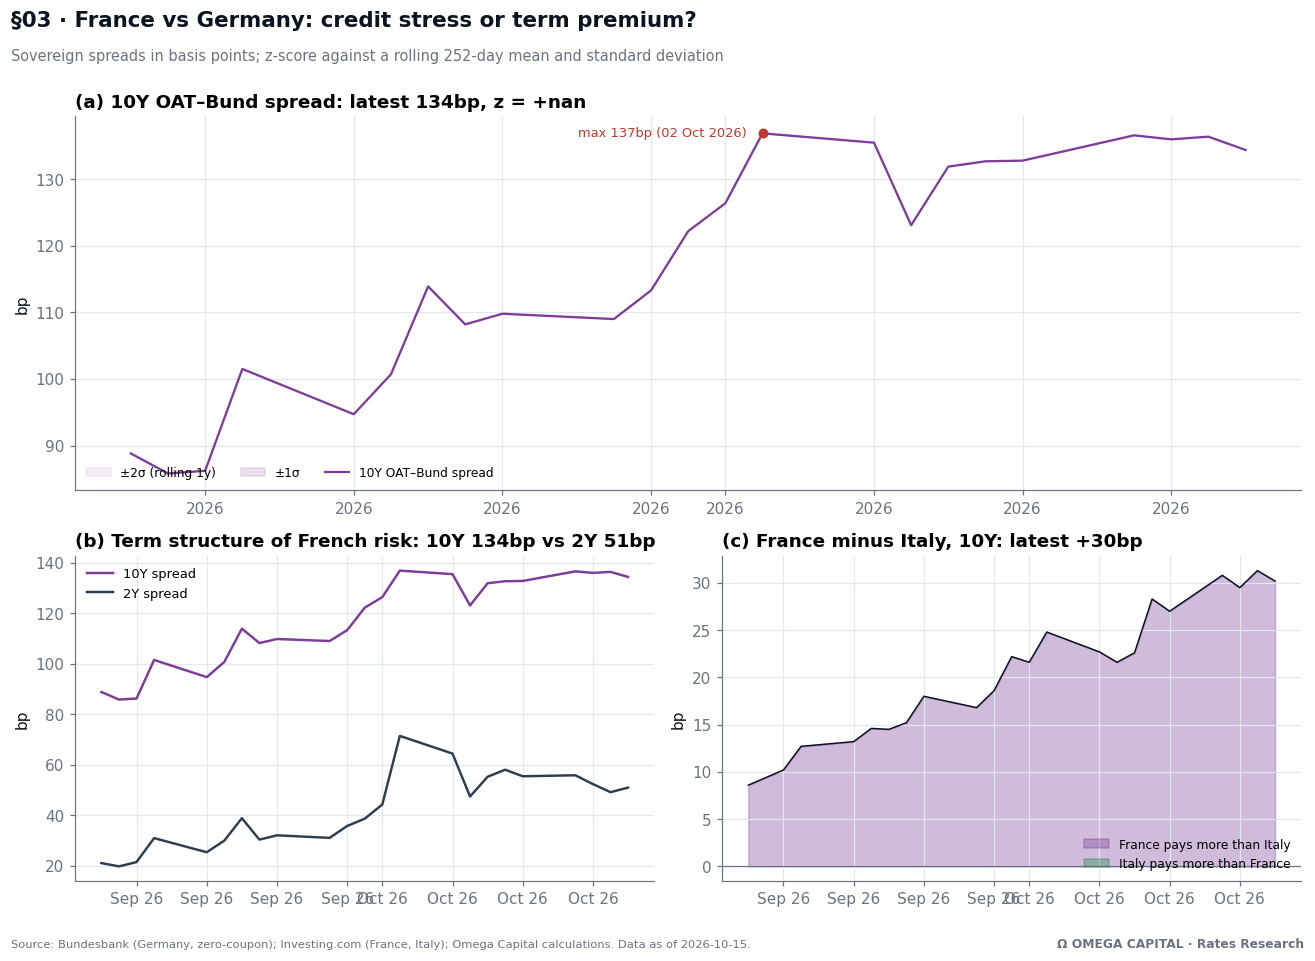

saved: charts/chart3_france_spreads.png


,value
10Y spread latest (bp),134
10Y spread 2026 max (bp),137 on 2026-10-02
10Y spread rolling z (latest),NaN
10Y spread percentile since 2016,74%
2Y spread latest (bp),51
10Y minus 2Y spread (bp),83
FR-IT 10Y latest (bp),30
First day France > Italy (since 2016),2026-09-15


In [5]:
need = {"FR_10Y", "DE_10Y", "FR_2Y", "DE_2Y", "IT_10Y"}
assert need <= set(px.columns), f"missing: {need - set(px.columns)}"

s10 = ((px["FR_10Y"] - px["DE_10Y"]) * 100).dropna()
s2 = ((px["FR_2Y"] - px["DE_2Y"]) * 100).dropna()
fi = ((px["FR_10Y"] - px["IT_10Y"]) * 100).dropna()

m, sd = s10.rolling(252, min_periods=120).mean(), s10.rolling(252, min_periods=120).std()
z = (s10 - m) / sd

fig = plt.figure(figsize=(12, 8.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1])
ax = fig.add_subplot(gs[0, :])
ax.fill_between(m.index, m - 2 * sd, m + 2 * sd, color=COL["FR"], alpha=0.08, label="±2σ (rolling 1y)")
ax.fill_between(m.index, m - sd, m + sd, color=COL["FR"], alpha=0.15, label="±1σ")
ax.plot(m.index, m, color=COL["FR"], lw=0.8, ls="--")
ax.plot(s10.index, s10, color=COL["FR"], lw=1.5, label="10Y OAT–Bund spread")
ax.scatter([s10.idxmax()], [s10.max()], color=COL["accent"], zorder=5, s=30)
right_half = s10.idxmax() > s10.index[len(s10) // 2]
ax.annotate(f"max {s10.max():.0f}bp ({s10.idxmax():%d %b %Y})", xy=(s10.idxmax(), s10.max()),
            xytext=(-10 if right_half else 10, 0), textcoords="offset points", fontsize=8.5,
            color=COL["accent"], va="center", ha="right" if right_half else "left")
for d, lbl in [("2017-04-21", "2017 election"), ("2022-04-10", "2022 election"),
               ("2024-06-09", "Assembly dissolved")]:
    d = pd.Timestamp(d)
    if s10.index[0] <= d <= s10.index[-1]:
        ax.axvline(d, color=COL["muted"], lw=0.7, ls=":")
        ax.text(d, ax.get_ylim()[1] * 0.97, " " + lbl, fontsize=7.5, color=COL["muted"], va="top")
ax.set_ylabel("bp"); ax.legend(loc="lower left", fontsize=8, ncol=3)
ax.set_title(f"(a) 10Y OAT–Bund spread: latest {s10.iloc[-1]:.0f}bp, z = {z.iloc[-1]:+.1f}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax = fig.add_subplot(gs[1, 0])
ax.plot(s10.loc["2024":].index, s10.loc["2024":], color=COL["FR"], lw=1.6, label="10Y spread")
ax.plot(s2.loc["2024":].index, s2.loc["2024":], color=COL["DE"], lw=1.6, label="2Y spread")
ax.set_ylabel("bp"); ax.legend(fontsize=8.5)
ax.set_title(f"(b) Term structure of French risk: 10Y {s10.iloc[-1]:.0f}bp vs 2Y {s2.iloc[-1]:.0f}bp")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

ax = fig.add_subplot(gs[1, 1])
f = fi.loc["2023":]
ax.fill_between(f.index, 0, f, where=f >= 0, color=COL["FR"], alpha=0.35, label="France pays more than Italy")
ax.fill_between(f.index, 0, f, where=f < 0, color=COL["IT"], alpha=0.35, label="Italy pays more than France")
ax.plot(f.index, f, color=COL["ink"], lw=1)
ax.axhline(0, color=COL["muted"], lw=0.8); ax.set_ylabel("bp"); ax.legend(fontsize=8, loc="lower right")
ax.set_title(f"(c) France minus Italy, 10Y: latest {fi.iloc[-1]:+.0f}bp")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

header(fig, "§03 · France vs Germany: credit stress or term premium?",
       "Sovereign spreads in basis points; z-score against a rolling 252-day mean and standard deviation")
finish(fig, "chart3_france_spreads", "Bundesbank (Germany, zero-coupon); Investing.com (France, Italy)")

cross = fi[fi > 0]
tbl3 = pd.Series({
    "10Y spread latest (bp)": round(s10.iloc[-1]),
    "10Y spread 2026 max (bp)": f"{s10.loc[BASE:].max():.0f} on {s10.loc[BASE:].idxmax().date()}",
    "10Y spread rolling z (latest)": round(z.iloc[-1], 2),
    "10Y spread percentile since 2016": f"{(s10 < s10.iloc[-1]).mean():.0%}",
    "2Y spread latest (bp)": round(s2.iloc[-1]),
    "10Y minus 2Y spread (bp)": round(s10.iloc[-1] - s2.iloc[-1]),
    "FR-IT 10Y latest (bp)": round(fi.iloc[-1]),
    "First day France > Italy (since 2016)": cross.index[0].date() if len(cross) else "never",
}, name="value")
display(tbl3.to_frame())

### §04 · Volatility regimes
- **Realised volatility:** the rolling 20-day standard deviation of daily bp changes, annualised (×√252).
- **Regime model:** a 2-state Markov-switching model on daily US 10Y changes, with a constant mean and switching variance:
  $\Delta y_t = \mu_{s_t} + \varepsilon_t$, where $\varepsilon_t \sim N(0, \sigma^2_{s_t})$ and $s_t \in \{\text{calm}, \text{stressed}\}$ follows a first-order Markov chain.

Shaded periods are days when the smoothed probability of the stressed regime is above 50%.

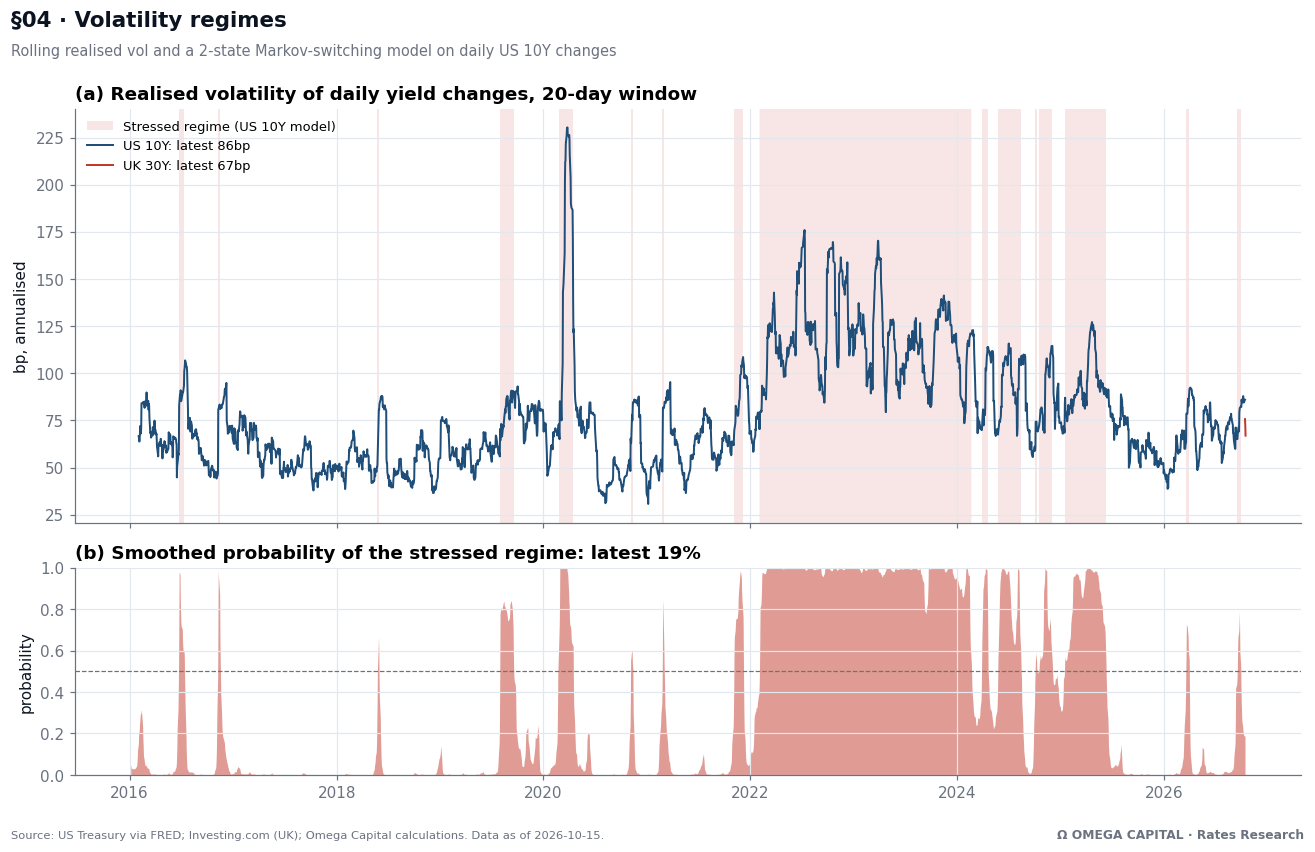

saved: charts/chart4_vol_regimes.png


,Daily vol (bp),Annualised vol (bp),Persistence Pr(stay),Expected duration (days),Share of days since 2016,Share of 2026 days
Calm,3.84,61.0,0.99,102.0,0.679,0.913
Stressed,7.39,117.0,0.98,49.0,0.321,0.087


Log-likelihood -8101.7 | AIC 16215.4 | n = 2694


In [7]:
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression

def rv(s, w=20):
    d = s.dropna().diff() * 100
    return d.rolling(w).std() * np.sqrt(252)

y = (px["US_10Y"].dropna().diff() * 100).dropna()
res = MarkovRegression(y.values, k_regimes=2, trend="c", switching_variance=True).fit(disp=False, search_reps=10)
names_ = list(res.model.param_names)
sig2 = np.asarray(res.params)[[i for i, n in enumerate(names_) if n.startswith("sigma2")]]
hi = int(np.argmax(sig2)); lo_ = 1 - hi
prob = pd.Series(np.asarray(res.smoothed_marginal_probabilities)[:, hi], index=y.index)
P = res.regime_transition[:, :, 0]                       # P[i, j] = Pr(s_t = i | s_t-1 = j)
stay_hi, stay_lo = P[hi, hi], P[lo_, lo_]

fig, axs = plt.subplots(2, 1, figsize=(12, 7.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax = axs[0]
ax.fill_between(prob.index, 0, 1, where=prob > 0.5, transform=ax.get_xaxis_transform(),
                color=COL["accent"], alpha=0.12, lw=0, label="Stressed regime (US 10Y model)")
for col, cc, lbl in [("US_10Y", "US", "US 10Y"), ("UK_30Y", "UK", "UK 30Y")]:
    if col in px:
        r = rv(px[col]); ax.plot(r.index, r, color=COL[cc], lw=1.3, label=f"{lbl}: latest {r.iloc[-1]:.0f}bp")
ax.set_ylabel("bp, annualised"); ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("(a) Realised volatility of daily yield changes, 20-day window")

ax = axs[1]
ax.fill_between(prob.index, 0, prob, color=COL["accent"], alpha=0.5, lw=0)
ax.axhline(0.5, color=COL["muted"], ls="--", lw=0.8)
ax.set_ylim(0, 1); ax.set_ylabel("probability")
ax.set_title(f"(b) Smoothed probability of the stressed regime: latest {prob.iloc[-1]:.0%}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

header(fig, "§04 · Volatility regimes",
       "Rolling realised vol and a 2-state Markov-switching model on daily US 10Y changes")
finish(fig, "chart4_vol_regimes", "US Treasury via FRED; Investing.com (UK)")

ann = np.sqrt(sig2 * 252)
tbl4 = pd.DataFrame({
    "Daily vol (bp)": np.sqrt(sig2)[[lo_, hi]].round(2),
    "Annualised vol (bp)": ann[[lo_, hi]].round(0),
    "Persistence Pr(stay)": [round(stay_lo, 3), round(stay_hi, 3)],
    "Expected duration (days)": [round(1 / (1 - stay_lo), 1), round(1 / (1 - stay_hi), 1)],
    "Share of days since 2016": [round((prob <= 0.5).mean(), 3), round((prob > 0.5).mean(), 3)],
    "Share of 2026 days": [round((prob.loc[BASE:] <= 0.5).mean(), 3), round((prob.loc[BASE:] > 0.5).mean(), 3)],
}, index=["Calm", "Stressed"])
display(tbl4)
print(f"Log-likelihood {res.llf:.1f} | AIC {res.aic:.1f} | n = {res.nobs}")

### §05 · Oil and yields
How sensitive is the US 10Y to oil? We regress the daily change in the 10Y yield (bp) on Brent's daily log return (%) over a rolling 60-day window:
$\Delta y_t = \alpha + \beta\, r^{oil}_t + \varepsilon_t$.

β is the bp move in the 10Y for a +1% move in Brent. The band is a 95% confidence interval.

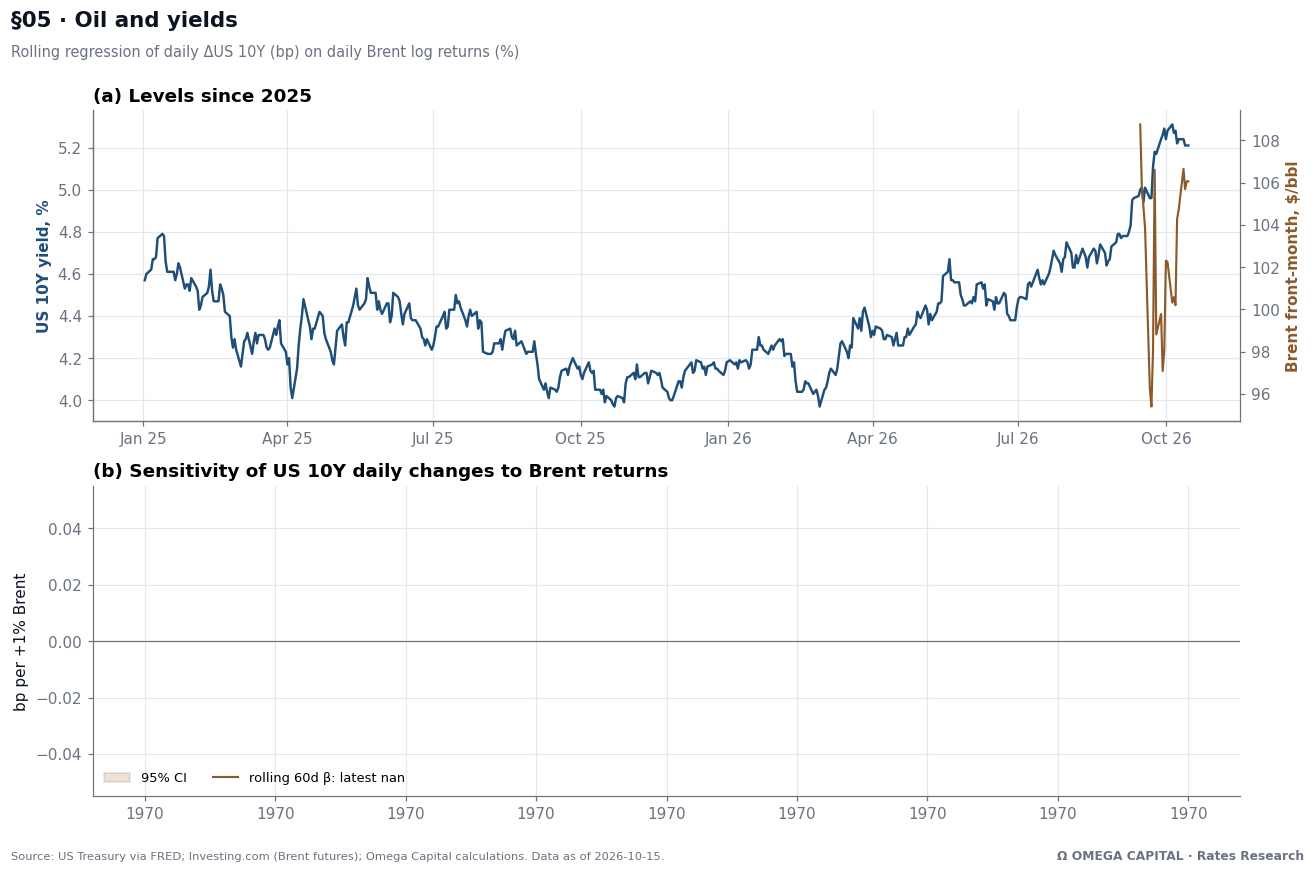

saved: charts/chart5_oil_yields.png


,β (bp per 1%),t-stat,corr,n
Window,,,,
2016–2025,NaN,NaN,NaN,0
2026 YTD,0.42,1.2,0.28,19
Last 60 days,0.42,1.2,0.28,19


In [8]:
oil = px["BRENT"].dropna(); oil = oil[oil > 0]
df = pd.concat({"r_oil": np.log(oil).diff() * 100, "dy": px["US_10Y"].dropna().diff() * 100}, axis=1).dropna()
# drop extreme oil days (futures roll artefacts / April 2020): keep |r| < 15%
df = df[df["r_oil"].abs() < 15]

W = 60
cov = df["dy"].rolling(W).cov(df["r_oil"]); var = df["r_oil"].rolling(W).var()
beta = cov / var
rho = df["dy"].rolling(W).corr(df["r_oil"])
se = np.sqrt((1 - rho ** 2) / (W - 2)) * df["dy"].rolling(W).std() / df["r_oil"].rolling(W).std()

def ols_beta(d):
    b = np.cov(d["dy"], d["r_oil"])[0, 1] / d["r_oil"].var()
    r = d["dy"].corr(d["r_oil"]); n = len(d)
    s = np.sqrt((1 - r ** 2) / (n - 2)) * d["dy"].std() / d["r_oil"].std()
    return b, s, r, n

fig, axs = plt.subplots(2, 1, figsize=(12, 7.8), gridspec_kw={"height_ratios": [1, 1]})
ax = axs[0]; lv = px[["US_10Y", "BRENT"]].loc["2025":]
ax.plot(lv.index, lv["US_10Y"].ffill(), color=COL["US"], lw=1.6, label="US 10Y yield (lhs, %)")
ax.set_ylabel("US 10Y yield, %", color=COL["US"], weight="bold")
ax2 = ax.twinx(); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax2.plot(lv.index, lv["BRENT"].ffill(), color=COL["BRENT"], lw=1.4, label="Brent front-month (rhs, $/bbl)")
ax2.set_ylabel("Brent front-month, $/bbl", color=COL["BRENT"], weight="bold")
ax.set_title("(a) Levels since 2025"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

ax = axs[1]; b = beta.loc["2019":]; s_ = se.loc["2019":]
ax.fill_between(b.index, b - 1.96 * s_, b + 1.96 * s_, color=COL["BRENT"], alpha=0.18, label="95% CI")
ax.plot(b.index, b, color=COL["BRENT"], lw=1.4, label=f"rolling {W}d β: latest {beta.iloc[-1]:.2f}")
ax.axhline(0, color=COL["muted"], lw=0.8)
ax.set_ylabel("bp per +1% Brent"); ax.legend(loc="lower left", fontsize=8.5, ncol=2)
ax.set_title("(b) Sensitivity of US 10Y daily changes to Brent returns")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

header(fig, "§05 · Oil and yields", "Rolling regression of daily ΔUS 10Y (bp) on daily Brent log returns (%)")
finish(fig, "chart5_oil_yields", "US Treasury via FRED; Investing.com (Brent futures)")

out = []
for lbl, d in [("2016–2025", df.loc[:"2025"]), ("2026 YTD", df.loc[BASE:]), (f"Last {W} days", df.iloc[-W:])]:
    b_, s__, r_, n_ = ols_beta(d)
    out.append({"Window": lbl, "β (bp per 1%)": round(b_, 2), "t-stat": round(b_ / s__, 1),
                "corr": round(r_, 2), "n": n_})
display(pd.DataFrame(out).set_index("Window"))

### Headline numbers for the report text

In [9]:
def ytd(col):
    s = px[col].loc[BASE:].dropna(); return (s.iloc[-1] - s.iloc[0]) * 100

us = px[US_T].dropna()
c0, c1 = us.loc[BASE:].iloc[0], us.iloc[-1]
lines = [
    f"US 10Y: {c1['US_10Y']:.2f}% ({ytd('US_10Y'):+.0f}bp YTD); 2026 high {px['US_10Y'].loc[BASE:].max():.2f}% on {px['US_10Y'].loc[BASE:].idxmax():%d %b}",
    f"US 2Y: {c1['US_2Y']:.2f}% ({ytd('US_2Y'):+.0f}bp YTD); US 30Y {c1['US_30Y']:.2f}% ({ytd('US_30Y'):+.0f}bp)",
    f"US 2s10s: {(c1['US_10Y']-c1['US_2Y'])*100:+.0f}bp (from {(c0['US_10Y']-c0['US_2Y'])*100:+.0f}bp); "
    f"5s30s: {(c1['US_30Y']-c1['US_5Y'])*100:+.0f}bp (from {(c0['US_30Y']-c0['US_5Y'])*100:+.0f}bp)",
    f"PCA: level explains {share[0]:.0%} of daily US curve moves since 2016; latest 120d window {roll.iloc[-1]:.0%}",
    f"30Y yields YTD: " + ", ".join(f"{k} {table1.loc[k, 'Change (bp)']:+d}bp" for k in table1.index),
    f"Worst 30Y par-bond price move: {table1['30Y par bond price chg (%)'].idxmin()} "
    f"{table1['30Y par bond price chg (%)'].min():.1f}%",
    f"OAT–Bund 10Y: {s10.iloc[-1]:.0f}bp (z {z.iloc[-1]:+.1f}); 2026 max {s10.loc[BASE:].max():.0f}bp; "
    f"2Y spread {s2.iloc[-1]:.0f}bp; FR–IT {fi.iloc[-1]:+.0f}bp",
    f"Vol regime: stressed-regime probability {prob.iloc[-1]:.0%} today; stressed on "
    f"{(prob.loc[BASE:] > 0.5).mean():.0%} of 2026 days vs {(prob > 0.5).mean():.0%} since 2016",
    f"Oil: 2026 β of US 10Y to Brent = {ols_beta(df.loc[BASE:])[0]:.2f}bp per +1% "
    f"(t = {ols_beta(df.loc[BASE:])[0] / ols_beta(df.loc[BASE:])[1]:.1f})",
]
print(f"Data as of {AS_OF}\n")
for l in lines: print("•", l)
print("\nCharts saved in:", FIG.resolve())

Data as of 2026-10-15

• US 10Y: 5.21% (+102bp YTD); 2026 high 5.31% on 05 Oct
• US 2Y: 4.79% (+132bp YTD); US 30Y 5.56% (+70bp)
• US 2s10s: +42bp (from +72bp); 5s30s: +56bp (from +112bp)
• PCA: level explains 81% of daily US curve moves since 2016; latest 120d window 83%
• 30Y yields YTD: US +70bp, JP +68bp, DE +28bp, FR +21bp, UK -9bp
• Worst 30Y par-bond price move: JP -11.7%
• OAT–Bund 10Y: 134bp (z +nan); 2026 max 137bp; 2Y spread 51bp; FR–IT +30bp
• Vol regime: stressed-regime probability 19% today; stressed on 9% of 2026 days vs 32% since 2016
• Oil: 2026 β of US 10Y to Brent = 0.42bp per +1% (t = 1.2)

Charts saved in: /Users/lwuqiu/bond-analysis/charts
